# Notebook 15 — Feature Engineering & Feature Selection

## Building Better Inputs for Machine Learning

**Program:** Data Science & AI  
**Stage:** Machine Learning  
**Business case:** AdventureWorks — Customer Purchase Prediction  
**Estimated teaching time:** 5 hours  
**Level:** Beginner to Intermediate

---

### Business context

AdventureWorks is an e-commerce business that sells electronics, home products, and accessories. The business team wants to identify customers who are likely to place another order within the next 30 days.

The available source data contains customer activity, order history, product preferences, and basic customer information. These raw fields are useful, but they are not always in the best form for a machine learning model.

In this notebook, you will create meaningful features from the available data, prepare them safely, and select a useful set of features for a predictive model.

> **Important:** All data in this notebook is synthetic and generated with a fixed random seed. It is designed for training and does not represent real customers.

### Learning outcomes

By the end of this notebook, you will be able to:

- Explain what a feature is and why feature engineering matters.
- Create numerical, categorical, date-based, and interaction features.
- Apply transformations such as binning and logarithmic scaling.
- Encode categorical variables and scale numerical variables.
- Build a preprocessing pipeline with `ColumnTransformer` and `Pipeline`.
- Explain the difference between feature selection and feature extraction.
- Apply filter, wrapper, and embedded feature selection methods.
- Interpret feature importance without confusing association with causation.
- Prevent data leakage by fitting transformations only on training data.
- Compare a baseline workflow with an engineered and selected feature workflow.

### Notebook map

1. Business problem and feature engineering workflow
2. Load and inspect the source data
3. Feature engineering foundations
4. Create business-focused features
5. Prepare features with preprocessing pipelines
6. Feature selection methods
7. Train and compare models
8. Interpret results and feature importance
9. Practical exercises
10. Final applied project
11. Summary and readiness checklist

## 1. Business Problem and Feature Engineering Workflow

### What is a feature?

A **feature** is an input variable used by a machine learning model to make a prediction. For example, a model that predicts whether a customer will purchase again may use:

- Number of orders in the last 90 days.
- Average order value.
- Number of days since the last order.
- Customer's preferred product category.

The target is the outcome that the model must predict. In this case, the target is `repeat_purchase_30d`.

### What is feature engineering?

**Feature engineering** is the process of creating, transforming, or improving input variables so that they represent useful patterns in the data.

A raw transaction date may not be directly useful in its original form. We can extract the month, weekday, or customer tenure from it. These new values may help a model identify patterns.

### What is feature selection?

**Feature selection** is the process of choosing a subset of available features for model training. It can help reduce noise, simplify a model, lower training time, and sometimes improve generalization.

Feature engineering creates or transforms inputs. Feature selection chooses which inputs to keep.

### The workflow

1. Understand the business question and prediction point in time.
2. Inspect the available source fields.
3. Create features using information available at prediction time.
4. Split data into training and test sets.
5. Fit preprocessing and feature selection on training data only.
6. Train and evaluate the model on unseen data.

**Instructor note:** Keep returning to the prediction point in time. A feature is only valid if its information would have been available when the prediction was made.

### 1.1 Define the prediction task

For this exercise, each row represents one customer snapshot.

- **Prediction date:** the date on which the business wants to score the customer.
- **Observation window:** the 90 days before the prediction date.
- **Prediction window:** the 30 days after the prediction date.
- **Target:** whether the customer places at least one order in the next 30 days.

This time structure is essential. Features must come from the observation window. The target comes from the future prediction window.

| Element | Definition |
|---|---|
| Unit of analysis | One customer snapshot |
| Observation window | Previous 90 days |
| Prediction window | Next 30 days |
| Target | `repeat_purchase_30d` |
| Business use | Prioritize relevant retention campaigns |

**Potential leakage:** using an order date, order count, or spending value from the 30-day prediction window as a feature would reveal information that was not available at prediction time.

## 2. Load and Inspect the Source Data

We will generate a compact customer-level dataset. The source fields are intentionally a mixture of numerical, categorical, and date-related information.

The data is created locally, so no download, external file, or API key is required.

In [1]:
import numpy as np
import pandas as pd

from IPython.display import display

RANDOM_STATE = 42
rng = np.random.default_rng(RANDOM_STATE)

n_customers = 1200
prediction_date = pd.Timestamp("2026-10-01")

customer_ids = [f"AW-C{number:05d}" for number in range(1, n_customers + 1)]

regions = rng.choice(
    ["North", "South", "East", "West"],
    size=n_customers,
    p=[0.28, 0.24, 0.22, 0.26]
)

segments = rng.choice(
    ["Consumer", "Corporate", "Small Business"],
    size=n_customers,
    p=[0.62, 0.23, 0.15]
)

preferred_categories = rng.choice(
    ["Electronics", "Home", "Accessories", "Office"],
    size=n_customers,
    p=[0.34, 0.27, 0.25, 0.14]
)

signup_days_ago = rng.integers(30, 2200, size=n_customers)
customer_signup_date = prediction_date - pd.to_timedelta(signup_days_ago, unit="D")

orders_90d = rng.poisson(lam=2.7, size=n_customers)
orders_90d = np.clip(orders_90d, 0, 14)

days_since_last_order = np.where(
    orders_90d > 0,
    rng.integers(1, 91, size=n_customers),
    rng.integers(91, 181, size=n_customers)
)

avg_order_value = np.clip(rng.gamma(shape=3.2, scale=28, size=n_customers), 12, 450)
total_spend_90d = orders_90d * avg_order_value * rng.uniform(0.75, 1.25, size=n_customers)

items_per_order = np.clip(rng.normal(loc=2.4, scale=0.8, size=n_customers), 1, 7)
discount_rate = np.clip(rng.beta(a=2, b=10, size=n_customers), 0, 0.45)
return_rate = np.clip(rng.beta(a=1.5, b=18, size=n_customers), 0, 0.6)

support_tickets_90d = rng.poisson(lam=0.55, size=n_customers)
website_sessions_30d = rng.poisson(lam=7, size=n_customers)
email_clicks_30d = rng.poisson(lam=1.8, size=n_customers)

last_order_date = prediction_date - pd.to_timedelta(days_since_last_order, unit="D")

customers = pd.DataFrame({
    "customer_id": customer_ids,
    "region": regions,
    "customer_segment": segments,
    "preferred_category": preferred_categories,
    "signup_date": customer_signup_date,
    "last_order_date": last_order_date,
    "days_since_last_order": days_since_last_order,
    "orders_90d": orders_90d,
    "avg_order_value": avg_order_value.round(2),
    "total_spend_90d": total_spend_90d.round(2),
    "items_per_order": items_per_order.round(2),
    "discount_rate": discount_rate.round(3),
    "return_rate": return_rate.round(3),
    "support_tickets_90d": support_tickets_90d,
    "website_sessions_30d": website_sessions_30d,
    "email_clicks_30d": email_clicks_30d
})

customers.head()

,customer_id,region,customer_segment,preferred_category,signup_date,last_order_date,days_since_last_order,orders_90d,avg_order_value,total_spend_90d,items_per_order,discount_rate,return_rate,support_tickets_90d,website_sessions_30d,email_clicks_30d
0,AW-C00001,West,Consumer,Home,2022-08-15,2026-08-21,41,2,52.07,115.74,2.55,0.229,0.025,0,6,4
1,AW-C00002,South,Consumer,Accessories,2024-12-18,2026-08-09,53,3,62.15,146.03,1.67,0.116,0.065,1,7,0
2,AW-C00003,West,Corporate,Accessories,2025-02-05,2026-05-07,147,0,86.25,0.00,1.00,0.130,0.032,1,5,2
3,AW-C00004,East,Corporate,Office,2025-11-23,2026-08-29,33,2,156.87,237.34,2.95,0.038,0.004,0,15,1
4,AW-C00005,North,Consumer,Accessories,2026-08-23,2026-09-03,28,2,34.27,68.87,1.70,0.197,0.142,1,5,3


### 2.1 Create the future outcome

The target is generated from a probability that depends on several customer signals. This creates a learnable training example while retaining some randomness.

The target is stored separately from the raw feature table. In a real project, the target would be created from verified future order records after the prediction window has closed.

In [2]:
logit = (
    -1.05
    + 0.20 * customers["orders_90d"]
    - 0.018 * customers["days_since_last_order"]
    + 0.012 * customers["website_sessions_30d"]
    + 0.16 * customers["email_clicks_30d"]
    - 0.75 * customers["return_rate"]
    + 0.0009 * customers["total_spend_90d"]
)

purchase_probability = 1 / (1 + np.exp(-logit))
customers["repeat_purchase_30d"] = rng.binomial(1, purchase_probability)

print("Dataset shape:", customers.shape)
print("Positive target rate:", round(customers["repeat_purchase_30d"].mean(), 3))
display(customers.head())

Dataset shape: (1200, 17)
Positive target rate: 0.327


,customer_id,region,customer_segment,preferred_category,signup_date,last_order_date,days_since_last_order,orders_90d,avg_order_value,total_spend_90d,items_per_order,discount_rate,return_rate,support_tickets_90d,website_sessions_30d,email_clicks_30d,repeat_purchase_30d
0,AW-C00001,West,Consumer,Home,2022-08-15,2026-08-21,41,2,52.07,115.74,2.55,0.229,0.025,0,6,4,0
1,AW-C00002,South,Consumer,Accessories,2024-12-18,2026-08-09,53,3,62.15,146.03,1.67,0.116,0.065,1,7,0,0
2,AW-C00003,West,Corporate,Accessories,2025-02-05,2026-05-07,147,0,86.25,0.00,1.00,0.130,0.032,1,5,2,0
3,AW-C00004,East,Corporate,Office,2025-11-23,2026-08-29,33,2,156.87,237.34,2.95,0.038,0.004,0,15,1,0
4,AW-C00005,North,Consumer,Accessories,2026-08-23,2026-09-03,28,2,34.27,68.87,1.70,0.197,0.142,1,5,3,0


### 2.2 Inspect data quality and variable types

Before engineering features, inspect the table. Confirm the number of rows, data types, missing values, and basic distributions.

The `customer_id` column is an identifier. It is useful for tracing records, but it should not normally be used as a predictive feature because its numeric or text pattern has no meaningful customer behavior.

In [3]:
customers.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1200 entries, 0 to 1199
Data columns (total 17 columns):
 #   Column                 Non-Null Count  Dtype         
---  ------                 --------------  -----         
 0   customer_id            1200 non-null   object        
 1   region                 1200 non-null   object        
 2   customer_segment       1200 non-null   object        
 3   preferred_category     1200 non-null   object        
 4   signup_date            1200 non-null   datetime64[ns]
 5   last_order_date        1200 non-null   datetime64[ns]
 6   days_since_last_order  1200 non-null   int64         
 7   orders_90d             1200 non-null   int64         
 8   avg_order_value        1200 non-null   float64       
 9   total_spend_90d        1200 non-null   float64       
 10  items_per_order        1200 non-null   float64       
 11  discount_rate          1200 non-null   float64       
 12  return_rate            1200 non-null   float64       
 13  sup

In [4]:
display(customers.describe(include="all").T)

,count,unique,top,freq,mean,min,25%,50%,75%,max,std
customer_id,1200,1200,AW-C00001,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
region,1200,4,North,338,NaN,NaN,NaN,NaN,NaN,NaN,NaN
customer_segment,1200,3,Consumer,770,NaN,NaN,NaN,NaN,NaN,NaN,NaN
preferred_category,1200,4,Electronics,408,NaN,NaN,NaN,NaN,NaN,NaN,NaN
signup_date,1200,NaN,NaN,NaN,2023-10-05 01:46:48,2020-09-24 00:00:00,2022-05-22 06:00:00,2023-10-15 00:00:00,2025-03-10 06:00:00,2026-09-01 00:00:00,NaN
last_order_date,1200,NaN,NaN,NaN,2026-08-09 05:18:00,2026-04-04 00:00:00,2026-07-19 00:00:00,2026-08-13 12:00:00,2026-09-07 00:00:00,2026-09-30 00:00:00,NaN
days_since_last_order,1200.0,NaN,NaN,NaN,52.779167,1.0,24.0,48.5,74.0,180.0,37.33875
orders_90d,1200.0,NaN,NaN,NaN,2.65,0.0,1.75,3.0,4.0,10.0,1.651193
avg_order_value,1200.0,NaN,NaN,NaN,89.344408,12.0,50.9575,80.615,116.495,450.0,51.740001
total_spend_90d,1200.0,NaN,NaN,NaN,238.072733,0.0,79.7825,174.45,326.185,1843.78,228.215811


In [5]:
missing_summary = customers.isna().sum().sort_values(ascending=False)
display(missing_summary[missing_summary > 0])

Series([], dtype: int64)

### Knowledge check

1. What does one row represent in this dataset?
2. Which columns describe customer behavior?
3. Why should `customer_id` usually be excluded from model features?
4. Which information belongs to the future prediction window?

**Expected reasoning:** each row is one customer snapshot; behavioral columns describe activity before the prediction date; the identifier is not a meaningful behavior signal; future orders define the target and must not be used as inputs.

## 3. Feature Engineering Foundations

Feature engineering should be driven by the business problem, not by creating as many columns as possible.

A useful feature should have:
- A clear definition.
- A valid business interpretation.
- Information available at prediction time.
- A reasonable data type and range.
- A relationship to the problem that can be tested.

### 3.1 Numerical features

Numerical features represent counts or measurements. Examples include order count, spending, discount rate, and days since last order.

Common transformations include:
- Ratios, such as average spending per order.
- Differences, such as customer tenure.
- Log transformations for highly skewed positive values.
- Caps or robust transformations when extreme values are present.

Always inspect the meaning and distribution before choosing a transformation.

array([[<Axes: title={'center': 'orders_90d'}>,
        <Axes: title={'center': 'avg_order_value'}>,
        <Axes: title={'center': 'total_spend_90d'}>],
       [<Axes: title={'center': 'items_per_order'}>,
        <Axes: title={'center': 'discount_rate'}>,
        <Axes: title={'center': 'return_rate'}>],
       [<Axes: title={'center': 'support_tickets_90d'}>,
        <Axes: title={'center': 'website_sessions_30d'}>,
        <Axes: title={'center': 'email_clicks_30d'}>]], dtype=object)

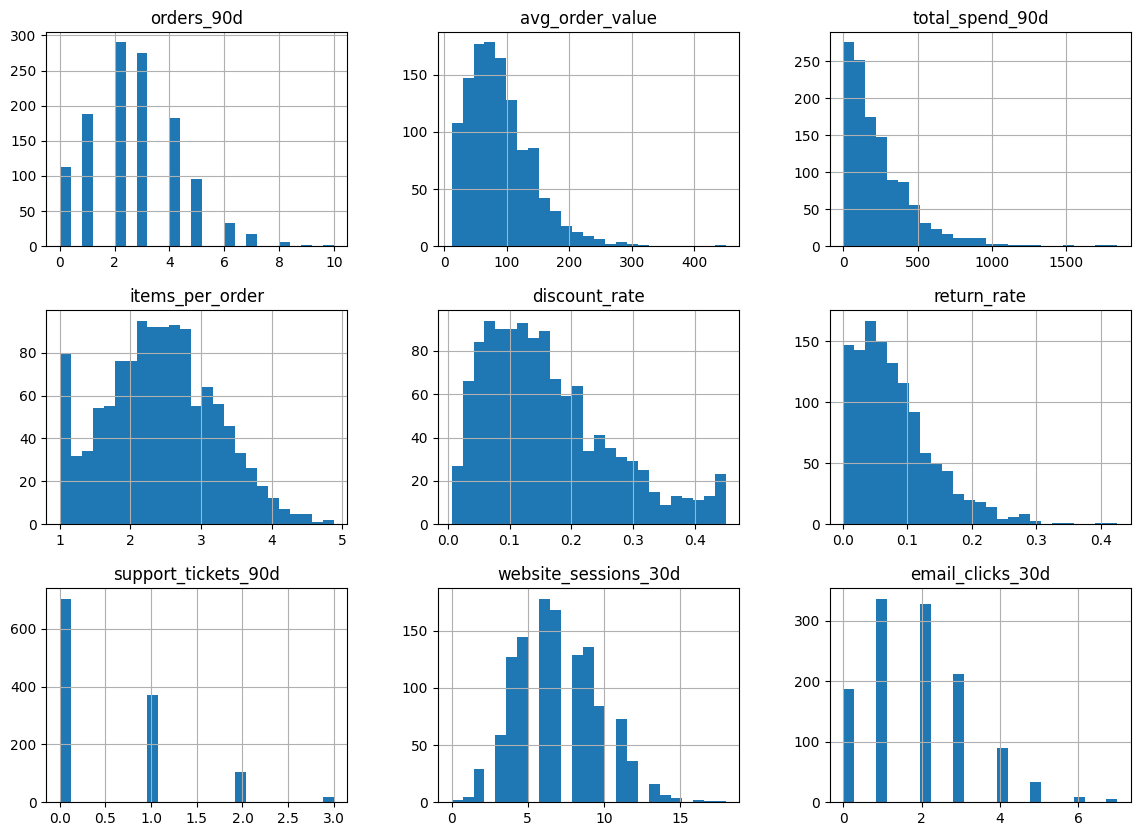

In [6]:
numeric_columns = [
    "orders_90d",
    "avg_order_value",
    "total_spend_90d",
    "items_per_order",
    "discount_rate",
    "return_rate",
    "support_tickets_90d",
    "website_sessions_30d",
    "email_clicks_30d"
]

customers[numeric_columns].hist(figsize=(14, 10), bins=25)

### 3.2 Create ratio and behavior features

A ratio can provide a more useful view than its original components. For example, `spend_per_order` represents the average spending per order over the observation window.

We must handle division by zero. Customers with no orders in the observation window should not produce infinite values.

In [7]:
feature_data = customers.copy()

feature_data["spend_per_order"] = np.where(
    feature_data["orders_90d"] > 0,
    feature_data["total_spend_90d"] / feature_data["orders_90d"],
    0
)

feature_data["sessions_per_order"] = (
    feature_data["website_sessions_30d"] /
    feature_data["orders_90d"].replace(0, np.nan)
).fillna(0)

feature_data["engagement_per_session"] = (
    feature_data["email_clicks_30d"] /
    feature_data["website_sessions_30d"].replace(0, np.nan)
).fillna(0)

display(feature_data[
    ["orders_90d", "total_spend_90d", "spend_per_order",
     "website_sessions_30d", "sessions_per_order", "engagement_per_session"]
].head())

,orders_90d,total_spend_90d,spend_per_order,website_sessions_30d,sessions_per_order,engagement_per_session
0,2,115.74,57.870000,6,3.000000,0.666667
1,3,146.03,48.676667,7,2.333333,0.000000
2,0,0.00,0.000000,5,0.000000,0.400000
3,2,237.34,118.670000,15,7.500000,0.066667
4,2,68.87,34.435000,5,2.500000,0.600000


**Interpretation:** `spend_per_order` separates order value from order frequency. `sessions_per_order` describes website activity relative to purchase frequency. These features may help a model distinguish frequent buyers from customers who browse often but purchase less frequently.

A ratio is not automatically better than its original columns. Compare model performance and check whether the feature adds useful information.

### 3.3 Date and time features

Dates often contain useful information, but raw date strings are difficult for many models to use directly.

We can derive:
- Customer tenure in days.
- Month of the last order.
- Day of the week of the last order.
- Whether the last order occurred on a weekend.

The date features must be calculated from dates available at the prediction time.

In [8]:
feature_data["customer_tenure_days"] = (
    prediction_date - feature_data["signup_date"]
).dt.days

feature_data["last_order_month"] = feature_data["last_order_date"].dt.month
feature_data["last_order_dayofweek"] = feature_data["last_order_date"].dt.dayofweek
feature_data["last_order_is_weekend"] = (
    feature_data["last_order_dayofweek"] >= 5
).astype(int)

display(feature_data[
    ["signup_date", "customer_tenure_days", "last_order_date",
     "last_order_month", "last_order_dayofweek", "last_order_is_weekend"]
].head())

,signup_date,customer_tenure_days,last_order_date,last_order_month,last_order_dayofweek,last_order_is_weekend
0,2022-08-15,1508,2026-08-21,8,4,0
1,2024-12-18,652,2026-08-09,8,6,1
2,2025-02-05,603,2026-05-07,5,3,0
3,2025-11-23,312,2026-08-29,8,5,1
4,2026-08-23,39,2026-09-03,9,3,0


**Important:** `dayofweek` uses Monday = 0 and Sunday = 6 in pandas. A weekend indicator is a simple binary feature derived from that value.

For a production system, make sure the prediction date is calculated separately for each customer snapshot. This notebook uses one shared snapshot date to keep the example focused.

### 3.4 Categorical features

Categorical features describe groups or labels rather than quantities. Examples include region, customer segment, and preferred product category.

Some algorithms require numeric input. We therefore need to encode categories into numeric representations. One-hot encoding creates a separate binary column for each category.

Do not assign arbitrary numeric labels to nominal categories unless the numeric order has a real meaning. For example, encoding North = 1, South = 2, East = 3, and West = 4 may incorrectly suggest that the regions have an order or distance.

In [9]:
display(feature_data["preferred_category"].value_counts())

preferred_category
Electronics    408
Home           313
Accessories    309
Office         170
Name: count, dtype: int64

### 3.5 Binning and discretization

Binning converts a continuous numerical feature into groups. For example, customer tenure can be grouped into new, developing, and established customers.

Binning can make patterns easier to explain, but it also removes detail. Choose meaningful boundaries and compare the binned feature with the original numerical feature.

In [10]:
feature_data["tenure_group"] = pd.cut(
    feature_data["customer_tenure_days"],
    bins=[0, 180, 730, np.inf],
    labels=["New", "Developing", "Established"],
    right=True
)

display(feature_data[
    ["customer_tenure_days", "tenure_group"]
].head(10))

,customer_tenure_days,tenure_group
0,1508,Established
1,652,Developing
2,603,Developing
3,312,Developing
4,39,New
5,1117,Established
6,2171,Established
7,507,Developing
8,985,Established
9,2060,Established


### 3.6 Log transformation for skewed data

Spending and count variables are often right-skewed. A log transformation can reduce the influence of very large values.

`np.log1p(x)` calculates `log(1 + x)`. It is useful for non-negative values because it can handle zero.

Do not apply a logarithm to negative values without choosing a suitable transformation first.

In [11]:
feature_data["log_total_spend_90d"] = np.log1p(feature_data["total_spend_90d"])

display(
    feature_data[["total_spend_90d", "log_total_spend_90d"]]
    .describe()
)

,total_spend_90d,log_total_spend_90d
count,1200.000000,1200.000000
mean,238.072733,4.750139
std,228.215811,1.729375
min,0.000000,0.000000
25%,79.782500,4.391760
50%,174.450000,5.167354
75%,326.185000,5.790525
max,1843.780000,7.520115


### 3.7 Interaction and polynomial features

An interaction feature combines two or more variables. It can represent a business relationship that is not visible from each variable alone.

For example, high spending combined with frequent orders may describe a different customer profile from high spending with only one order.

Polynomial features can add squared or interaction terms. They can increase model flexibility, but also increase the number of features and the risk of overfitting. Use them selectively.

In [12]:
feature_data["orders_x_avg_value"] = (
    feature_data["orders_90d"] * feature_data["avg_order_value"]
)

feature_data["discount_x_orders"] = (
    feature_data["discount_rate"] * feature_data["orders_90d"]
)

display(feature_data[
    ["orders_90d", "avg_order_value", "orders_x_avg_value",
     "discount_rate", "discount_x_orders"]
].head())

,orders_90d,avg_order_value,orders_x_avg_value,discount_rate,discount_x_orders
0,2,52.07,104.14,0.229,0.458
1,3,62.15,186.45,0.116,0.348
2,0,86.25,0.00,0.130,0.000
3,2,156.87,313.74,0.038,0.076
4,2,34.27,68.54,0.197,0.394


### 3.8 A compact feature engineering function

Reusable transformations help keep training and scoring logic consistent. In this example, the function receives a DataFrame and returns a copy with derived features.

This function only uses columns available at prediction time. It does not use the target.

In [13]:
def create_customer_features(data):
    """Create customer behavior features from pre-prediction data."""
    result = data.copy()

    result["spend_per_order"] = np.where(
        result["orders_90d"] > 0,
        result["total_spend_90d"] / result["orders_90d"],
        0
    )

    result["sessions_per_order"] = (
        result["website_sessions_30d"] /
        result["orders_90d"].replace(0, np.nan)
    ).fillna(0)

    result["customer_tenure_days"] = (
        prediction_date - result["signup_date"]
    ).dt.days

    result["last_order_month"] = result["last_order_date"].dt.month
    result["last_order_dayofweek"] = result["last_order_date"].dt.dayofweek
    result["last_order_is_weekend"] = (
        result["last_order_dayofweek"] >= 5
    ).astype(int)

    result["tenure_group"] = pd.cut(
        result["customer_tenure_days"],
        bins=[0, 180, 730, np.inf],
        labels=["New", "Developing", "Established"]
    )

    result["log_total_spend_90d"] = np.log1p(result["total_spend_90d"])
    result["orders_x_avg_value"] = (
        result["orders_90d"] * result["avg_order_value"]
    )

    return result

engineered_data = create_customer_features(customers)
display(engineered_data.head())

,customer_id,region,customer_segment,preferred_category,signup_date,last_order_date,days_since_last_order,orders_90d,avg_order_value,total_spend_90d,items_per_order,discount_rate,return_rate,support_tickets_90d,website_sessions_30d,email_clicks_30d,repeat_purchase_30d,spend_per_order,sessions_per_order,customer_tenure_days,last_order_month,last_order_dayofweek,last_order_is_weekend,tenure_group,log_total_spend_90d,orders_x_avg_value
0,AW-C00001,West,Consumer,Home,2022-08-15,2026-08-21,41,2,52.07,115.74,2.55,0.229,0.025,0,6,4,0,57.870000,3.000000,1508,8,4,0,Established,4.759949,104.14
1,AW-C00002,South,Consumer,Accessories,2024-12-18,2026-08-09,53,3,62.15,146.03,1.67,0.116,0.065,1,7,0,0,48.676667,2.333333,652,8,6,1,Developing,4.990637,186.45
2,AW-C00003,West,Corporate,Accessories,2025-02-05,2026-05-07,147,0,86.25,0.00,1.00,0.130,0.032,1,5,2,0,0.000000,0.000000,603,5,3,0,Developing,0.000000,0.00
3,AW-C00004,East,Corporate,Office,2025-11-23,2026-08-29,33,2,156.87,237.34,2.95,0.038,0.004,0,15,1,0,118.670000,7.500000,312,8,5,1,Developing,5.473698,313.74
4,AW-C00005,North,Consumer,Accessories,2026-08-23,2026-09-03,28,2,34.27,68.87,1.70,0.197,0.142,1,5,3,0,34.435000,2.500000,39,9,3,0,New,4.246636,68.54


### Exercise 1 — Create two business features

Create the following features in a copy of `customers`:

1. `support_tickets_per_order`: support tickets divided by order count. Use zero when order count is zero.
2. `clicks_per_session`: email clicks divided by website sessions. Use zero when sessions are zero.

Then display the source columns and the two new features for the first ten customers.

**Challenge:** Explain one possible business interpretation for each feature.

In [14]:
# Student workspace

exercise_data = customers.copy()

# TODO: Create support_tickets_per_order safely.

# TODO: Create clicks_per_session safely.

# TODO: Display the relevant columns.

<details>
<summary><strong>Instructor solution — Exercise 1</strong></summary>

```python
exercise_data = customers.copy()

exercise_data["support_tickets_per_order"] = (
    exercise_data["support_tickets_90d"] /
    exercise_data["orders_90d"].replace(0, np.nan)
).fillna(0)

exercise_data["clicks_per_session"] = (
    exercise_data["email_clicks_30d"] /
    exercise_data["website_sessions_30d"].replace(0, np.nan)
).fillna(0)

display(exercise_data[
    ["support_tickets_90d", "orders_90d", "support_tickets_per_order",
     "email_clicks_30d", "website_sessions_30d", "clicks_per_session"]
].head(10))
```

</details>

## 4. Build a Modeling Dataset

We now create the modeling table. The target is separated from the features, and identifiers and raw date columns are excluded from the model input.

Some original variables are retained alongside engineered variables. This allows the model and feature selection process to determine which information is useful.

In [15]:
target = "repeat_purchase_30d"

drop_from_features = [
    "customer_id",
    "repeat_purchase_30d",
    "signup_date",
    "last_order_date"
]

X = engineered_data.drop(columns=drop_from_features)
y = engineered_data[target].copy()

print("Feature matrix shape:", X.shape)
print("Target shape:", y.shape)
print("Target classes:")
print(y.value_counts(normalize=True).rename("proportion"))

Feature matrix shape: (1200, 22)
Target shape: (1200,)
Target classes:
repeat_purchase_30d
0    0.673333
1    0.326667
Name: proportion, dtype: float64


### 4.1 Train-test split

The test set must represent unseen data. We use a stratified split to preserve the target class proportions in both sets.

For a real deployment with customer snapshots collected over time, a time-based split may be more appropriate. Random splitting is used here because this synthetic dataset contains one snapshot per customer and the purpose is to teach feature engineering and selection.

In [16]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y
)

print("Training rows:", len(X_train))
print("Test rows:", len(X_test))
print("Training positive rate:", round(y_train.mean(), 3))
print("Test positive rate:", round(y_test.mean(), 3))

Training rows: 960
Test rows: 240
Training positive rate: 0.327
Test positive rate: 0.325


## 5. Preprocessing with Pipelines

Machine learning algorithms often require numerical inputs with consistent formats and scales.

A preprocessing pipeline makes the steps repeatable and reduces the risk of data leakage.

### 5.1 Common preprocessing steps

**Numerical columns**
- Impute missing values using the training-set median.
- Scale values when the selected model benefits from scaling.

**Categorical columns**
- Impute missing values using the most frequent category.
- Apply one-hot encoding.
- Ignore unseen categories during transformation.

A `ColumnTransformer` applies different transformations to different column groups. A `Pipeline` connects preprocessing and model training into one workflow.

In [17]:
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

numeric_features = X_train.select_dtypes(include=["number"]).columns.tolist()
categorical_features = X_train.select_dtypes(include=["object", "category"]).columns.tolist()

numeric_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer(
    transformers=[
        ("numeric", numeric_pipeline, numeric_features),
        ("categorical", categorical_pipeline, categorical_features)
    ],
    remainder="drop"
)

print("Numerical features:", len(numeric_features))
print("Categorical features:", len(categorical_features))

Numerical features: 18
Categorical features: 4


### 5.2 Fit on training data, transform both sets

The preprocessor learns values such as medians, means, standard deviations, and category levels from the training data only.

The test set is transformed using those learned values. It must not be used to fit the preprocessing steps.

In [18]:
X_train_prepared = preprocessor.fit_transform(X_train)
X_test_prepared = preprocessor.transform(X_test)

print("Prepared training shape:", X_train_prepared.shape)
print("Prepared test shape:", X_test_prepared.shape)

Prepared training shape: (960, 32)
Prepared test shape: (240, 32)


### 5.3 Inspect transformed feature names

One-hot encoding expands one categorical column into multiple binary columns. The transformed feature names help us understand the final model input.

Depending on the transformer and library version, the output may be a sparse matrix. We can inspect the names without converting the full matrix to a dense array.

In [19]:
transformed_feature_names = preprocessor.get_feature_names_out()

print("Number of transformed features:", len(transformed_feature_names))
print(transformed_feature_names[:25])

Number of transformed features: 32
['numeric__days_since_last_order' 'numeric__orders_90d'
 'numeric__avg_order_value' 'numeric__total_spend_90d'
 'numeric__items_per_order' 'numeric__discount_rate'
 'numeric__return_rate' 'numeric__support_tickets_90d'
 'numeric__website_sessions_30d' 'numeric__email_clicks_30d'
 'numeric__spend_per_order' 'numeric__sessions_per_order'
 'numeric__customer_tenure_days' 'numeric__last_order_month'
 'numeric__last_order_dayofweek' 'numeric__last_order_is_weekend'
 'numeric__log_total_spend_90d' 'numeric__orders_x_avg_value'
 'categorical__region_East' 'categorical__region_North'
 'categorical__region_South' 'categorical__region_West'
 'categorical__customer_segment_Consumer'
 'categorical__customer_segment_Corporate'
 'categorical__customer_segment_Small Business']


### Exercise 2 — Inspect the preprocessing output

1. Count the numerical and categorical source features.
2. Find the transformed columns that begin with `categorical__`.
3. Explain why one categorical source feature may become several transformed columns.
4. Explain why `fit_transform` is used on training data but only `transform` on test data.

<details>
<summary><strong>Instructor solution — Exercise 2</strong></summary>

```python
categorical_output_names = [
    name for name in transformed_feature_names
    if name.startswith("categorical__")
]

print("Categorical transformed columns:", len(categorical_output_names))
print(categorical_output_names)

# One-hot encoding creates a separate indicator column for each category.
# The preprocessor is fitted on training data to avoid learning from the test set.
```

</details>

## 6. Feature Selection

Feature selection chooses a subset of the available input variables.

### Why select features?

- Reduce unnecessary complexity.
- Reduce training time and memory use.
- Remove irrelevant or redundant variables.
- Improve interpretability.
- Sometimes improve generalization.

Feature selection is not guaranteed to improve model performance. It must be tested using an appropriate validation strategy.

### Three broad families

| Family | How it works | Example |
|---|---|---|
| Filter | Scores features using statistical measures before model fitting | VarianceThreshold, mutual information |
| Wrapper | Evaluates subsets by repeatedly fitting a model | Recursive Feature Elimination |
| Embedded | Selects or ranks features during model fitting | L1 regularization, tree importance |

We will explore each family with practical examples.

### 6.1 Filter method — VarianceThreshold

A feature with the same value for every training row contains no variation. It cannot separate observations in that training set.

`VarianceThreshold` removes features with variance below a chosen threshold. It is a simple filter method and does not use the target variable.

In [20]:
from sklearn.feature_selection import VarianceThreshold

variance_filter = VarianceThreshold(threshold=0.0)
X_train_variance = variance_filter.fit_transform(X_train_prepared)
X_test_variance = variance_filter.transform(X_test_prepared)

variance_mask = variance_filter.get_support()
variance_kept_names = transformed_feature_names[variance_mask]

print("Before variance filtering:", X_train_prepared.shape[1])
print("After variance filtering:", X_train_variance.shape[1])
print("Removed features:", int((~variance_mask).sum()))

Before variance filtering: 32
After variance filtering: 32
Removed features: 0


### 6.2 Filter method — Mutual Information

Mutual information measures how much information a feature provides about the target. It can detect non-linear relationships, unlike simple linear correlation.

For classification, use `mutual_info_classif`. The score is non-negative; higher values indicate more estimated information about the target.

The scores are estimates and should not be treated as proof of causation.

In [21]:
from sklearn.feature_selection import mutual_info_classif

mi_scores = mutual_info_classif(
    X_train_variance,
    y_train,
    random_state=RANDOM_STATE
)

mi_ranking = (
    pd.DataFrame({
        "feature": variance_kept_names,
        "mutual_information": mi_scores
    })
    .sort_values("mutual_information", ascending=False)
)

display(mi_ranking.head(15))

,feature,mutual_information
1,numeric__orders_90d,0.055452
28,categorical__preferred_category_Office,0.048855
6,numeric__return_rate,0.045426
16,numeric__log_total_spend_90d,0.043954
3,numeric__total_spend_90d,0.043759
11,numeric__sessions_per_order,0.042225
13,numeric__last_order_month,0.037345
0,numeric__days_since_last_order,0.032896
17,numeric__orders_x_avg_value,0.030318
10,numeric__spend_per_order,0.028838


### 6.3 Select the top K features

`SelectKBest` keeps the K features with the highest scores from a scoring function.

The value of K is a modeling choice. It should be selected using validation data or cross-validation, not by repeatedly checking the final test set.

In [22]:
from sklearn.feature_selection import SelectKBest, mutual_info_classif

k = min(15, X_train_variance.shape[1])

select_k_best = SelectKBest(
    score_func=mutual_info_classif,
    k=k
)

X_train_kbest = select_k_best.fit_transform(X_train_variance, y_train)
X_test_kbest = select_k_best.transform(X_test_variance)

kbest_mask = select_k_best.get_support()
kbest_names = variance_kept_names[kbest_mask]

print("Selected features:", len(kbest_names))
print(kbest_names.tolist())

Selected features:

 15
['numeric__days_since_last_order', 'numeric__orders_90d', 'numeric__total_spend_90d', 'numeric__return_rate', 'numeric__spend_per_order', 'numeric__sessions_per_order', 'numeric__last_order_month', 'numeric__log_total_spend_90d', 'numeric__orders_x_avg_value', 'categorical__region_North', 'categorical__customer_segment_Corporate', 'categorical__preferred_category_Accessories', 'categorical__preferred_category_Electronics', 'categorical__preferred_category_Home', 'categorical__tenure_group_New']


### 6.4 Wrapper method — Recursive Feature Elimination

Recursive Feature Elimination (RFE) repeatedly fits an estimator, ranks features using the estimator, and removes the least important features until the requested number remains.

RFE can be computationally expensive because it fits the estimator multiple times. It is useful when the number of features is manageable and the estimator provides a feature importance measure or coefficients.

For this demonstration, we use a Random Forest classifier and select a small number of features.

In [23]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.feature_selection import RFE

rfe_estimator = RandomForestClassifier(
    n_estimators=120,
    random_state=RANDOM_STATE,
    class_weight="balanced",
    n_jobs=-1
)

n_select = min(12, X_train_variance.shape[1])

rfe = RFE(
    estimator=rfe_estimator,
    n_features_to_select=n_select,
    step=1
)

X_train_rfe = rfe.fit_transform(X_train_variance, y_train)
X_test_rfe = rfe.transform(X_test_variance)

rfe_names = variance_kept_names[rfe.get_support()]

print("RFE selected features:", len(rfe_names))
print(rfe_names.tolist())

RFE selected features: 12
['numeric__days_since_last_order', 'numeric__avg_order_value', 'numeric__total_spend_90d', 'numeric__items_per_order', 'numeric__discount_rate', 'numeric__return_rate', 'numeric__website_sessions_30d', 'numeric__spend_per_order', 'numeric__sessions_per_order', 'numeric__customer_tenure_days', 'numeric__log_total_spend_90d', 'numeric__orders_x_avg_value']


### 6.5 Embedded method — L1 regularization

L1 regularization can shrink some model coefficients to exactly zero. Features with zero coefficients are not used by the fitted linear model.

This is an embedded feature selection approach because selection happens as part of model fitting.

The effect depends on feature scaling and the regularization strength. We use a pipeline so that scaling and model fitting happen together.

In [24]:
from sklearn.linear_model import LogisticRegression

l1_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("model", LogisticRegression(
        penalty="l1",
        solver="liblinear",
        C=0.15,
        max_iter=2000,
        random_state=RANDOM_STATE
    ))
])

l1_pipeline.fit(X_train_variance, y_train)

l1_coefficients = l1_pipeline.named_steps["model"].coef_[0]

l1_ranking = (
    pd.DataFrame({
        "feature": variance_kept_names,
        "coefficient": l1_coefficients,
        "absolute_coefficient": np.abs(l1_coefficients)
    })
    .sort_values("absolute_coefficient", ascending=False)
)

display(l1_ranking.head(20))
print("Features with zero coefficients:", int(np.isclose(l1_coefficients, 0).sum()))

/opt/pyvenv/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(
/opt/pyvenv/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:1160: UserWarning: Inconsistent values: penalty=l1 with l1_ratio=0.0. penalty is deprecated. Please use l1_ratio only.
  warnings.warn(


,feature,coefficient,absolute_coefficient
0,numeric__days_since_last_order,-0.574570,0.574570
1,numeric__orders_90d,0.367469,0.367469
9,numeric__email_clicks_30d,0.189304,0.189304
17,numeric__orders_x_avg_value,0.157212,0.157212
28,categorical__preferred_category_Office,0.134388,0.134388
12,numeric__customer_tenure_days,0.060843,0.060843
24,categorical__customer_segment_Small Business,-0.054260,0.054260
31,categorical__tenure_group_New,0.044095,0.044095
21,categorical__region_West,0.040428,0.040428
10,numeric__spend_per_order,-0.035391,0.035391


Features with zero coefficients: 16


### 6.6 Embedded method — Tree-based feature importance

Tree-based models can estimate feature importance from the reduction in impurity across splits.

These values are useful for exploration, but they have limitations:
- They can favor features with many possible split points.
- Correlated features can share or distort importance.
- Importance does not prove that a feature causes the target.

Use validation performance and domain knowledge alongside importance scores.

In [25]:
tree_model = RandomForestClassifier(
    n_estimators=250,
    min_samples_leaf=5,
    class_weight="balanced",
    random_state=RANDOM_STATE,
    n_jobs=-1
)

tree_model.fit(X_train_variance, y_train)

tree_importance = (
    pd.DataFrame({
        "feature": variance_kept_names,
        "importance": tree_model.feature_importances_
    })
    .sort_values("importance", ascending=False)
)

display(tree_importance.head(15))

,feature,importance
0,numeric__days_since_last_order,0.110668
17,numeric__orders_x_avg_value,0.076722
3,numeric__total_spend_90d,0.074171
16,numeric__log_total_spend_90d,0.069484
10,numeric__spend_per_order,0.068346
11,numeric__sessions_per_order,0.060111
12,numeric__customer_tenure_days,0.058580
4,numeric__items_per_order,0.055141
6,numeric__return_rate,0.053943
5,numeric__discount_rate,0.051127


### 6.7 Compare feature selection methods

Different methods may select different features because they use different definitions of usefulness.

- Mutual information measures statistical dependence with the target.
- RFE evaluates features through a particular estimator.
- L1 regularization selects features through coefficient shrinkage.
- Tree importance measures impurity reduction within a fitted tree ensemble.

There is no universal feature ranking that is best for every model and dataset.

In [26]:
selection_comparison = pd.DataFrame({
    "method": ["Mutual Information", "RFE", "L1 Logistic Regression", "Random Forest Importance"],
    "selected_or_ranked_features": [
        mi_ranking.head(k)["feature"].tolist(),
        rfe_names.tolist(),
        l1_ranking.loc[l1_ranking["absolute_coefficient"] > 1e-8, "feature"].head(k).tolist(),
        tree_importance.head(k)["feature"].tolist()
    ]
})

display(selection_comparison)

,method,selected_or_ranked_features
0,Mutual Information,"[numeric__orders_90d, categorical__preferred_c..."
1,RFE,"[numeric__days_since_last_order, numeric__avg_..."
2,L1 Logistic Regression,"[numeric__days_since_last_order, numeric__orde..."
3,Random Forest Importance,"[numeric__days_since_last_order, numeric__orde..."


### Exercise 3 — Compare selection strategies

Using the results above:

1. List the top five features according to mutual information.
2. List the features selected by RFE.
3. Identify any features that appear in more than one method.
4. Explain why the methods may disagree.
5. Would you remove a feature only because one method ranked it low? Explain.

**Instructor guidance:** Encourage students to compare evidence rather than search for one universally correct list.

<details>
<summary><strong>Instructor solution — Exercise 3</strong></summary>

```python
top_five_mi = mi_ranking.head(5)["feature"].tolist()
rfe_selected = rfe_names.tolist()

common_features = sorted(set(top_five_mi).intersection(rfe_selected))

print("Top five MI:", top_five_mi)
print("RFE selected:", rfe_selected)
print("Shared features:", common_features)
```

Methods disagree because they use different criteria and model assumptions. A low score from one method is not sufficient evidence to remove a feature without validation.
</details>

## 7. Evaluate Feature Sets with a Consistent Model

A feature selection method should be evaluated by its effect on predictive performance and practical complexity.

We will compare:
1. All preprocessed features.
2. Features selected by mutual information.
3. Features selected by RFE.

The selection methods were fitted on training data only. The test set remains untouched until this final comparison.

In [27]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score
from sklearn.base import clone

def evaluate_classifier(model, X_fit, y_fit, X_eval, y_eval):
    model.fit(X_fit, y_fit)
    predictions = model.predict(X_eval)
    probabilities = model.predict_proba(X_eval)[:, 1]

    return {
        "accuracy": accuracy_score(y_eval, predictions),
        "precision": precision_score(y_eval, predictions, zero_division=0),
        "recall": recall_score(y_eval, predictions, zero_division=0),
        "f1": f1_score(y_eval, predictions, zero_division=0),
        "roc_auc": roc_auc_score(y_eval, probabilities)
    }

comparison_model = RandomForestClassifier(
    n_estimators=250,
    min_samples_leaf=5,
    class_weight="balanced",
    random_state=RANDOM_STATE,
    n_jobs=-1
)

results = []

for label, train_matrix, test_matrix in [
    ("All features after preprocessing", X_train_prepared, X_test_prepared),
    ("Mutual Information top K", X_train_kbest, X_test_kbest),
    ("RFE selected features", X_train_rfe, X_test_rfe)
]:
    metrics = evaluate_classifier(
        clone(comparison_model),
        train_matrix,
        y_train,
        test_matrix,
        y_test
    )
    results.append({
        "feature_set": label,
        "number_of_features": train_matrix.shape[1],
        **metrics
    })

results_df = pd.DataFrame(results).sort_values("roc_auc", ascending=False)
display(results_df.round(3))

,feature_set,number_of_features,accuracy,precision,recall,f1,roc_auc
2,RFE selected features,12,0.671,0.493,0.449,0.470,0.704
0,All features after preprocessing,32,0.667,0.487,0.474,0.481,0.704
1,Mutual Information top K,15,0.650,0.463,0.487,0.475,0.700


### 7.1 Interpret the comparison

Do not select a feature set based on one metric alone.

Consider:
- Predictive performance.
- Number of features.
- Stability across validation folds.
- Ease of explanation.
- Data collection and maintenance cost.
- Whether the selected features are available at scoring time.

A smaller feature set may be preferable when performance is similar and the model is easier to maintain.

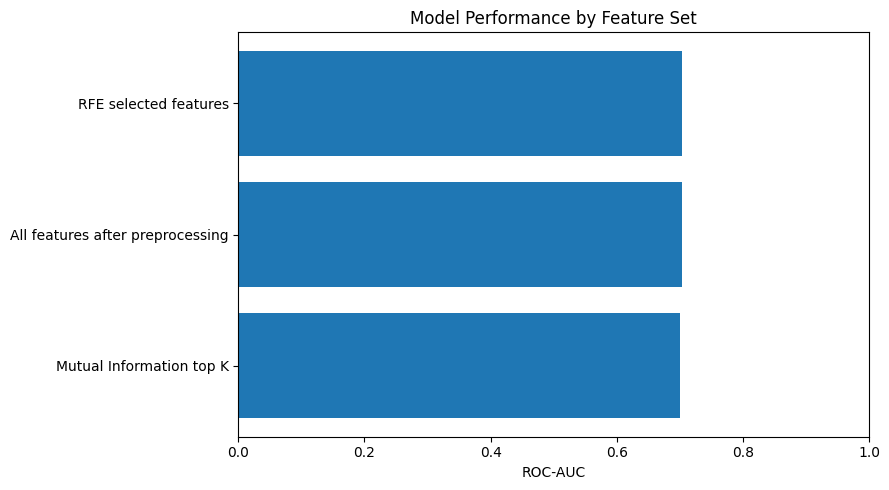

In [28]:
import matplotlib.pyplot as plt

plot_data = results_df.sort_values("roc_auc")

plt.figure(figsize=(9, 5))
plt.barh(plot_data["feature_set"], plot_data["roc_auc"])
plt.xlabel("ROC-AUC")
plt.title("Model Performance by Feature Set")
plt.xlim(0, 1)
plt.tight_layout()
plt.show()

## 8. Feature Importance and Interpretation

Feature importance helps explain which inputs a fitted model relies on. It does not explain every individual prediction, and it does not establish causality.

### 8.1 Permutation importance

Permutation importance measures how much a model's score decreases when one feature is randomly shuffled. If shuffling a feature reduces performance, the model may rely on that feature.

It should be calculated on data that was not used to fit the model. We will use the test set only for this final explanatory analysis, after model comparison.

In [29]:
from sklearn.inspection import permutation_importance

final_model = clone(comparison_model)
final_model.fit(X_train_prepared, y_train)

permutation_result = permutation_importance(
    final_model,
    X_test_prepared,
    y_test,
    n_repeats=8,
    random_state=RANDOM_STATE,
    scoring="roc_auc",
    n_jobs=-1
)

permutation_table = (
    pd.DataFrame({
        "feature": transformed_feature_names,
        "importance_mean": permutation_result.importances_mean,
        "importance_std": permutation_result.importances_std
    })
    .sort_values("importance_mean", ascending=False)
)

display(permutation_table.head(15))

Spreadsheet runtime warmup failed during python startup
Traceback (most recent call last):
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/rpc/client.py", line 152, in call
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/rpc/client.py", line 114, in _recv_one_line
ConnectionResetError: [Errno 104] Connection reset by peer

The above exception was the direct cause of the following exception:

Traceback (most recent call last):
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/patches/warm_spreadsheet_runtime_on_startup.py", line 26, in warm_spreadsheet_runtime_on_startup
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/spreadsheet_warmup.py", line 776, in warm_spreadsheet_runtime
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/spreadsheet_warmup.py", line 62, in _populate_warmup_workbook
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/generated/interface/models.py", line 38270, in ge

Spreadsheet runtime warmup failed during python startup
Traceback (most recent call last):
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/patches/warm_spreadsheet_runtime_on_startup.py", line 26, in warm_spreadsheet_runtime_on_startup
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/spreadsheet_warmup.py", line 785, in warm_spreadsheet_runtime
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/spreadsheet_warmup.py", line 718, in _warm_feature_flows
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/spreadsheet_warmup.py", line 509, in _warm_drawing_and_image_flows
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/generated/interface/models.py", line 32861, in bring_to_front
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/rpc/remote.py", line 764, in __call__
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/rpc/client.py", line 175, in call
artifact_tool.rpc.client.Remot

Spreadsheet runtime warmup failed during python startup
Traceback (most recent call last):
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/patches/warm_spreadsheet_runtime_on_startup.py", line 26, in warm_spreadsheet_runtime_on_startup
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/spreadsheet_warmup.py", line 785, in warm_spreadsheet_runtime
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/spreadsheet_warmup.py", line 718, in _warm_feature_flows
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/spreadsheet_warmup.py", line 509, in _warm_drawing_and_image_flows
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/generated/interface/models.py", line 32861, in bring_to_front
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/rpc/remote.py", line 764, in __call__
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/rpc/client.py", line 175, in call
artifact_tool.rpc.client.Remot

Spreadsheet runtime warmup failed during python startup
Traceback (most recent call last):
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/patches/warm_spreadsheet_runtime_on_startup.py", line 26, in warm_spreadsheet_runtime_on_startup
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/spreadsheet_warmup.py", line 785, in warm_spreadsheet_runtime
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/spreadsheet_warmup.py", line 718, in _warm_feature_flows
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/spreadsheet_warmup.py", line 509, in _warm_drawing_and_image_flows
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/generated/interface/models.py", line 32861, in bring_to_front
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/rpc/remote.py", line 764, in __call__
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/rpc/client.py", line 175, in call
artifact_tool.rpc.client.Remot

Spreadsheet runtime warmup failed during python startup
Traceback (most recent call last):
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/patches/warm_spreadsheet_runtime_on_startup.py", line 26, in warm_spreadsheet_runtime_on_startup
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/spreadsheet_warmup.py", line 785, in warm_spreadsheet_runtime
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/spreadsheet_warmup.py", line 718, in _warm_feature_flows
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/spreadsheet_warmup.py", line 509, in _warm_drawing_and_image_flows
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/generated/interface/models.py", line 32861, in bring_to_front
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/rpc/remote.py", line 764, in __call__
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/rpc/client.py", line 175, in call
artifact_tool.rpc.client.Remot

,feature,importance_mean,importance_std
0,numeric__days_since_last_order,0.046791,0.023356
9,numeric__email_clicks_30d,0.010090,0.004755
1,numeric__orders_90d,0.009586,0.005148
13,numeric__last_order_month,0.008765,0.007571
2,numeric__avg_order_value,0.008715,0.002543
11,numeric__sessions_per_order,0.004095,0.005280
10,numeric__spend_per_order,0.003472,0.005395
6,numeric__return_rate,0.003443,0.001597
22,categorical__customer_segment_Consumer,0.002641,0.001901
12,numeric__customer_tenure_days,0.001840,0.004012


### 8.2 Visualize permutation importance

A positive importance value means the model score decreased after shuffling the feature. Values near zero suggest that the model did not rely strongly on that feature in this evaluation. Negative values can occur due to sampling variation or because the feature adds noise.

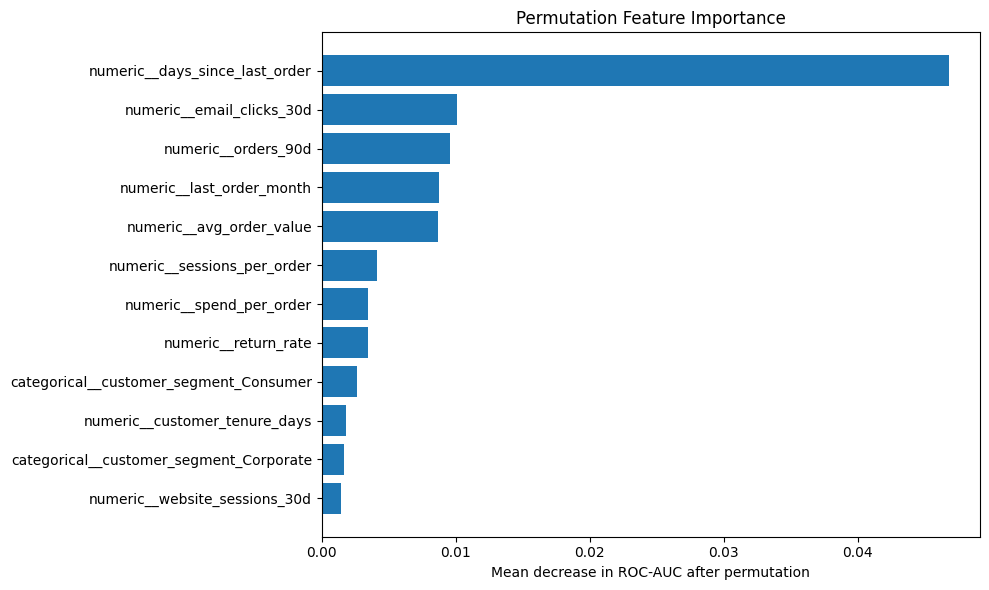

In [30]:
top_importance = permutation_table.head(12).sort_values("importance_mean")

plt.figure(figsize=(10, 6))
plt.barh(top_importance["feature"], top_importance["importance_mean"])
plt.xlabel("Mean decrease in ROC-AUC after permutation")
plt.title("Permutation Feature Importance")
plt.tight_layout()
plt.show()

### 8.3 Correlated features and importance

When two features contain similar information, a model may use either one. Shuffling one feature may have a small effect because the other feature still provides similar information.

For this reason:
- Inspect feature relationships and domain meaning.
- Avoid interpreting importance as a causal effect.
- Consider grouping highly correlated features.
- Confirm important findings on additional data when possible.

## 9. Practical Exercises

Complete these exercises before moving to the final project. The student workspaces are intentionally left unfinished.

### Exercise 4 — Engineer a customer loyalty feature

Create a new feature named `loyalty_value_score` using:
- `orders_90d`
- `avg_order_value`
- `customer_tenure_days`

Use this formula:

`orders_90d * avg_order_value / (1 + customer_tenure_days / 365)`

Then:
1. Add the feature to a copy of `engineered_data`.
2. Display its minimum, median, and maximum.
3. Explain why the feature might be useful.
4. Explain one limitation of this formula.

In [31]:
# Student workspace

exercise_4_data = engineered_data.copy()

# TODO: Create loyalty_value_score.

# TODO: Display descriptive statistics.

<details>
<summary><strong>Instructor solution — Exercise 4</strong></summary>

```python
exercise_4_data = engineered_data.copy()

exercise_4_data["loyalty_value_score"] = (
    exercise_4_data["orders_90d"] *
    exercise_4_data["avg_order_value"] /
    (1 + exercise_4_data["customer_tenure_days"] / 365)
)

display(exercise_4_data["loyalty_value_score"].describe())
```

This score combines purchase frequency, order value, and tenure. It is a teaching feature, not a validated business KPI. Its formula and usefulness should be tested rather than assumed.
</details>

### Exercise 5 — Compare different values of K

Use `SelectKBest` with mutual information to test at least three values of K. For each value:
1. Fit the selector using training data only.
2. Transform the training and test matrices.
3. Train the same Random Forest model.
4. Record ROC-AUC and the number of selected features.
5. Compare the results.

Do not use the test set to choose K repeatedly in a real project. Use cross-validation on the training set for model selection, then evaluate the chosen workflow once on the test set.

In [32]:
# Student workspace

k_values = [5, 10, 15]

# TODO: Loop through k_values.
# TODO: Fit SelectKBest on X_train_variance and y_train.
# TODO: Transform train and test data.
# TODO: Evaluate a consistent model and store the results.

<details>
<summary><strong>Instructor solution — Exercise 5</strong></summary>

```python
k_results = []

for candidate_k in k_values:
    selector = SelectKBest(
        score_func=mutual_info_classif,
        k=min(candidate_k, X_train_variance.shape[1])
    )

    train_selected = selector.fit_transform(X_train_variance, y_train)
    test_selected = selector.transform(X_test_variance)

    metrics = evaluate_classifier(
        clone(comparison_model),
        train_selected,
        y_train,
        test_selected,
        y_test
    )

    k_results.append({
        "k": train_selected.shape[1],
        **metrics
    })

display(pd.DataFrame(k_results).round(3))
```

For a production-quality selection process, evaluate candidate K values through cross-validation within the training data. Keep the test set for final evaluation.
</details>

## 10. Final Applied Project — AdventureWorks Customer Retention Features

### Business brief

The AdventureWorks marketing team wants to improve its customer retention campaign. The team has requested a model that identifies customers who are likely to make another purchase within the next 30 days.

Your task is to build a reproducible feature engineering and feature selection workflow.

### Project requirements

**Task 1 — Understand the data**
- Identify the unit of analysis, observation window, prediction date, and target.
- Separate identifiers and target from model inputs.
- Identify any fields that could cause leakage.

**Task 2 — Engineer features**
Create at least four features, including:
- One ratio feature.
- One date-based feature.
- One customer behavior feature.
- One interaction or transformed feature.

**Task 3 — Prepare the data**
- Split into training and test sets.
- Use numerical and categorical preprocessing pipelines.
- Ensure transformations are fitted only on training data.

**Task 4 — Select features**
Apply at least two different feature selection methods. Compare the selected features and explain why the methods may disagree.

**Task 5 — Train and evaluate**
- Train a classification model.
- Compare the all-feature workflow with a selected-feature workflow.
- Report ROC-AUC, precision, recall, and F1-score.
- Explain the trade-off between model simplicity and predictive performance.

**Task 6 — Communicate findings**
Prepare a short business summary containing:
- The most useful engineered features.
- The feature selection method used.
- Model performance.
- Important limitations.
- A recommendation for the marketing team.

### Deliverable

Submit:
1. Your completed notebook.
2. A feature dictionary describing each engineered feature.
3. A model comparison table.
4. A short business recommendation.

### Evaluation rubric

| Assessment area | Weight |
|---|---:|
| Data understanding and leakage awareness | 15% |
| Quality and relevance of engineered features | 25% |
| Correct preprocessing workflow | 20% |
| Feature selection and comparison | 20% |
| Model evaluation and interpretation | 10% |
| Clarity of business recommendations | 10% |
| **Total** | **100%** |

### Project workspace

Use this cell to record the engineered feature names and their business definitions. Add your final model comparison below it.

In [33]:
# Student project workspace

feature_dictionary = pd.DataFrame(columns=[
    "feature_name",
    "source_columns",
    "calculation",
    "business_interpretation",
    "available_at_prediction_time"
])

display(feature_dictionary)

,feature_name,source_columns,calculation,business_interpretation,available_at_prediction_time


## 11. Summary and Key Takeaways

In this notebook, you learned that strong machine learning results depend not only on the algorithm, but also on the quality and suitability of its input features.

Key ideas:

1. A feature must be available at the prediction time.
2. Feature engineering should be guided by the business problem.
3. Numerical, categorical, and date variables may need different transformations.
4. Pipelines help make preprocessing repeatable and reduce data leakage.
5. Filter, wrapper, and embedded methods use different approaches to feature selection.
6. Feature selection must be evaluated; it does not guarantee better performance.
7. Feature importance is useful for interpretation, but it does not prove causality.
8. Keep the test set separate from feature selection and model development.

### Readiness checklist

Before moving to the next unit, confirm that you can:

- [ ] Explain the difference between a feature and a target.
- [ ] Explain feature engineering and feature selection.
- [ ] Create ratio, date-based, binned, and interaction features.
- [ ] Apply one-hot encoding and numerical scaling.
- [ ] Build a `ColumnTransformer` and `Pipeline`.
- [ ] Explain why preprocessing must be fitted on training data only.
- [ ] Apply mutual information, RFE, and L1-based selection.
- [ ] Compare models trained on different feature sets.
- [ ] Interpret permutation importance carefully.
- [ ] Identify and prevent feature leakage.

### Recommended next step

Continue to **Unsupervised Learning & Clustering**, where you will use customer behavior data to discover groups without a target variable.

## References and Further Reading

Use the official documentation as the primary technical reference:

- [Scikit-learn — Preprocessing data](https://scikit-learn.org/stable/modules/preprocessing.html)
- [Scikit-learn — ColumnTransformer](https://scikit-learn.org/stable/modules/generated/sklearn.compose.ColumnTransformer.html)
- [Scikit-learn — Feature selection](https://scikit-learn.org/stable/modules/feature_selection.html)
- [Scikit-learn — Pipeline and composite estimators](https://scikit-learn.org/stable/modules/compose.html)
- [Scikit-learn — Permutation feature importance](https://scikit-learn.org/stable/modules/permutation_importance.html)
- [Pandas — Working with text, date, and time data](https://pandas.pydata.org/docs/user_guide/timeseries.html)

---

**End of Notebook 15 — Feature Engineering & Feature Selection**